# SrTiO3 (HSE06): the effect of exact exchange on the gap

Compares eigenvalues with the semi-local Hamiltonian alone against the same
Hamiltonian with the k-resolved exact exchange added
(`read_hamiltonian(exchange=True)`, see `sisl.io.fhiaims.add_exact_exchange`),
at the 8 k-points of the 2x2x2 SCF grid actually used in this hybrid-functional
run (`symmetry_reduced_k_grid .false.`, so all 8 are independent, unreduced
k-points -- this and the reader's own exactness checks only hold *at* these
SCF k-points, not at an arbitrary point on a band path; see
`techs/sisl-40-io.md` in the sisl repo for why).

5 atoms, 3 species, with real orbital radial functions from `output basis`
loaded automatically alongside H/S -- this run combines both the hybrid-EXX
and the real-orbital-basis features.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from sisl.io.fhiaims.rs import rsSileFHIaims
from sisl.io.fhiaims.exx import _read_kpoints
import re

DATA = "../srtio3_hse_exx/"

def read_fermi_level(aims_out):
    pat = re.compile(r"Chemical potential \(Fermi level\):\s*([-\d.]+) eV")
    Ef = None
    for line in open(aims_out):
        m = pat.search(line)
        if m:
            Ef = float(m.group(1))
    return Ef

Ef = read_fermi_level(DATA + "aims.out")
kpts, _ = _read_kpoints(DATA + "aims.out")
print(f"{len(kpts)} SCF k-points, Ef = {Ef:.4f} eV")


8 SCF k-points, Ef = -9.0183 eV


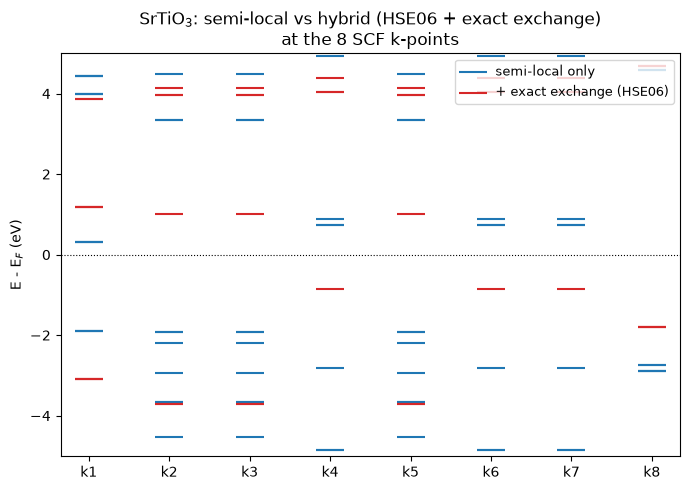

HOMO-LUMO gap at each k-point (eV):
  k1: semi-local = 0.443   hybrid = 4.270
  k2: semi-local = 1.151   hybrid = 4.710
  k3: semi-local = 1.151   hybrid = 4.710
  k4: semi-local = 2.690   hybrid = 4.906
  k5: semi-local = 1.151   hybrid = 4.710
  k6: semi-local = 2.690   hybrid = 4.906
  k7: semi-local = 2.690   hybrid = 4.906
  k8: semi-local = 3.555   hybrid = 6.493
minimum (indirect) gap: semi-local = 0.443 eV, hybrid = 4.270 eV


In [2]:
H_semilocal = rsSileFHIaims(DATA + "rs_indices.out").read_hamiltonian()
H_hybrid = rsSileFHIaims(DATA + "rs_indices.out").read_hamiltonian(
    exchange=True, directory=DATA, verbose=False
)

n_occ = 84 // 2  # Sr(38) + Ti(22) + 3*O(8) electrons, all-electron, doubly occupied

fig, ax = plt.subplots(figsize=(7, 5))
gaps_sl, gaps_hy = [], []
for ik, k in enumerate(kpts):
    e_sl = np.linalg.eigvalsh(H_semilocal.Hk(k=k, format="array")) - Ef
    e_hy = np.linalg.eigvalsh(H_hybrid.Hk(k=k, format="array")) - Ef
    ax.scatter([ik] * e_sl.size, e_sl, marker="_", s=400, color="tab:blue",
               label="semi-local only" if ik == 0 else None)
    ax.scatter([ik] * e_hy.size, e_hy, marker="_", s=400, color="tab:red",
               label="+ exact exchange (HSE06)" if ik == 0 else None)
    gaps_sl.append(e_sl[n_occ] - e_sl[n_occ - 1])
    gaps_hy.append(e_hy[n_occ] - e_hy[n_occ - 1])

ax.axhline(0.0, color="k", ls=":", lw=0.8)
ax.set_xticks(range(len(kpts)))
ax.set_xticklabels([f"k{i + 1}" for i in range(len(kpts))])
ax.set_ylabel("E - E$_F$ (eV)")
ax.set_ylim(-5, 5)
ax.legend(loc="upper right", fontsize=9)
ax.set_title("SrTiO$_3$: semi-local vs hybrid (HSE06 + exact exchange)\nat the 8 SCF k-points")
fig.tight_layout()
plt.show()

print("HOMO-LUMO gap at each k-point (eV):")
for ik in range(len(kpts)):
    print(f"  k{ik + 1}: semi-local = {gaps_sl[ik]:.3f}   hybrid = {gaps_hy[ik]:.3f}")
print(f"minimum (indirect) gap: semi-local = {min(gaps_sl):.3f} eV, hybrid = {min(gaps_hy):.3f} eV")


Adding the exact exchange opens the gap substantially at every k-point (as
expected: hybrid functionals correct semi-local DFT's well-known gap
underestimate by pushing occupied levels down and empty levels up) --
confirming the two separately-validated features (reading H/S, and adding
exact exchange from FHI-aims' own ELSI-CSC k-resolved exchange dump) compose
into physically sensible results, not just numerically self-consistent ones.